# 01 · Data audit: Give Me Some Credit

**Goal:** check the quality of the raw data before any cleaning or modelling. This notebook only *reads* `data/raw/`; it changes and saves nothing. Each issue found is collected in **section 7**, together with the handling rule proposed for the cleaning step.

**Files**

- `cs-training.csv`: 150,000 borrowers with the target `SeriousDlqin2yrs` (90+ days past due within the next two years).
- `cs-test.csv`: 101,503 borrowers without the target.
- `Data Dictionary.xls`: column definitions.

## 1. Load and first look

In [40]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path("../data/raw/cs-training.csv")
df = pd.read_csv(DATA_PATH)

df.head()


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [41]:
print(f"Rows: {len(df):,}  Columns: {df.shape[1]}")
df.dtypes

Rows: 150,000  Columns: 12


Unnamed: 0                                int64
SeriousDlqin2yrs                          int64
RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse      int64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                   int64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse      int64
NumberOfDependents                      float64
dtype: object

`Unnamed: 0` is a 1-based row number written by the CSV export, not a borrower attribute. It is checked again in section 6.

## 2. Missing values

In [42]:
display(df.isna().sum().sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())

MonthlyIncome                           29731
NumberOfDependents                       3924
Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
dtype: int64

Duplicate rows: 0


In [43]:
missing = df.isna().sum()
missing_summary = (
    pd.DataFrame({
        "missing_count": missing, 
        "missing_percent": (missing / len(df) * 100).round(2)

    })
    .query("missing_count > 0")
    .sort_values("missing_percent", ascending=False)
)

display(missing_summary)

,missing_count,missing_percent
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


In [44]:
df.groupby(df["MonthlyIncome"].isna())["SeriousDlqin2yrs"].agg(
    ['count', 'mean']
)

,count,mean
MonthlyIncome,,
False,120269,0.069486
True,29731,0.056137


In [45]:
df.groupby(df["NumberOfDependents"].isna())["SeriousDlqin2yrs"].agg(
    ['count', 'mean']
)

,count,mean
NumberOfDependents,,
False,146076,0.067410
True,3924,0.045617


In [46]:
# Is every row with missing NumberOfDependents also missing MonthlyIncome?
pd.crosstab(
    df["MonthlyIncome"].isna().rename("MonthlyIncome missing"),
    df["NumberOfDependents"].isna().rename("NumberOfDependents missing"),
)

NumberOfDependents missing,False,True
MonthlyIncome missing,,
False,120269,0
True,25807,3924


**Findings**

- `MonthlyIncome` is missing for 19.8% of rows and `NumberOfDependents` for 2.6%. Every row missing dependents is also missing income.
- Missingness is related to the target: borrowers with missing income default less often (5.6% vs 6.9%), and so do borrowers with missing dependents (4.6% vs 6.7%).
- Dropping these rows would remove a fifth of the data and bias the sample. Keep them, impute, and add missing-value flags so the model can still use the signal.

## 3. Duplicates

The check in section 2 reports 0 duplicates, but only because `Unnamed: 0` is different on every row. Repeat the check without it.

In [47]:
records = df.drop(columns="Unnamed: 0")
feature_cols = list(records.columns.drop("SeriousDlqin2yrs"))

exact_dup = records.duplicated(keep=False)
conflicting = (
    records.groupby(feature_cols, dropna=False)["SeriousDlqin2yrs"].transform("nunique") > 1
)

print("Rows that have an exact twin:            ", exact_dup.sum())
print("Extra copies (rows a dedup would remove):", records.duplicated().sum())
print("Rows with a feature twin but other target:", conflicting.sum())
print(f"Duplicated rows with MonthlyIncome missing: {records.loc[exact_dup, 'MonthlyIncome'].isna().mean():.0%}")

Rows that have an exact twin:             960
Extra copies (rows a dedup would remove): 609
Rows with a feature twin but other target: 145
Duplicated rows with MonthlyIncome missing: 85%


In [48]:
records.loc[exact_dup].sort_values(feature_cols).head(6)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
134365,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
137102,0,0.0,21,0,0.0,0.0,1,0,0,0,0.0
25632,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
83552,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
139345,0,0.0,21,0,0.0,820.0,2,0,0,0,0.0
100594,0,0.0,21,0,0.0,NaN,1,0,0,0,0.0


**Findings**

- Ignoring the row number, 609 rows are extra copies of another row (0.4% of the data). Most of them have missing income and sparse, common profiles, so they may be different borrowers who look the same. Without a real borrower ID this cannot be decided.
- 145 rows belong to groups that share all features but have different target values. That is label noise the model has to live with.
- Proposal: drop exact duplicates from the training data before splitting, so the same row cannot end up in both a training and a validation fold. Losing 0.4% of rows costs little.

## 4. Target

In [49]:
df["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

In [50]:
target_share = df["SeriousDlqin2yrs"].value_counts(normalize=True)
print(f"Default rate: {target_share[1]:.2%} (about 1 in {1 / target_share[1]:.0f} borrowers)")
print(f"Accuracy of a model that always predicts 'no default': {target_share[0]:.2%}")

Default rate: 6.68% (about 1 in 15 borrowers)
Accuracy of a model that always predicts 'no default': 93.32%


**Findings**

- The classes are imbalanced: 6.7% defaults. Accuracy is not useful here, because predicting "no default" for everyone already scores 93.3%.
- Use ROC-AUC (the competition metric) and PR-AUC, and stratify every train/validation split on the target.

## 5. Value ranges and outliers

In [51]:
display(df.describe(include="all").T)


,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,150000.0,75000.500000,43301.414527,1.0,37500.750000,75000.500000,112500.250000,150000.0
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0


Several columns break their expected range:

- `age` has a minimum of 0.
- The three past-due counts reach 98, while their 75th percentile is 0.
- `RevolvingUtilizationOfUnsecuredLines` is a ratio but reaches 50,708.
- `DebtRatio` reaches 329,664 and `MonthlyIncome` reaches 3,008,750.

The cell below shows the first suspicious rows; each column is then checked on its own.

In [52]:
# Các dòng có tuổi bằng 0
display(df.loc[df["age"] == 0])

# Các dòng có chỉ số rất lớn
display(
    df.loc[
        (df["RevolvingUtilizationOfUnsecuredLines"] > 1)
        | (df["DebtRatio"] > 10)
        | (df["NumberOfTime30-59DaysPastDueNotWorse"] >= 90)
    ].head(10)
)

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
65695,65696,0,1.0,0,1,0.436927,6000.0,6,0,2,0,2.0


,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
6,7,0,0.305682,57,0,5710.0,NaN,8,0,3,0,0.0
8,9,0,0.116951,27,0,46.0,NaN,2,0,0,0,NaN
14,15,0,0.019657,76,0,477.0,0.0,6,0,1,0,0.0
16,17,0,0.061086,78,0,2058.0,NaN,10,0,2,0,0.0
32,33,0,0.083418,62,0,977.0,NaN,6,0,1,0,0.0
41,42,0,0.072898,81,0,75.0,NaN,7,0,0,0,0.0
44,45,0,0.368876,68,0,1687.5,1.0,31,0,1,0,0.0
50,51,0,0.818978,73,0,3095.0,0.0,9,0,1,1,0.0
58,59,0,0.541109,43,0,2477.0,NaN,3,0,1,0,2.0
62,63,0,0.101156,72,0,1720.0,NaN,12,0,2,0,0.0


### 5.1 Age

In [53]:
print("Rows with age = 0:", (df["age"] == 0).sum())
print("Unnamed: 0 is unique:", df["Unnamed: 0"].is_unique)

display(
    df.loc[df["age"] == 0, [
        "Unnamed: 0",
        "SeriousDlqin2yrs",
        "age",
        "MonthlyIncome",
        "DebtRatio",
    ]]
)

Rows with age = 0: 1
Unnamed: 0 is unique: True


,Unnamed: 0,SeriousDlqin2yrs,age,MonthlyIncome,DebtRatio
65695,65696,0,0,6000.0,0.436927


In [54]:
print("Age < 18: ", (df["age"] < 18).sum())
print("Age > 100:", (df["age"] > 100).sum(), "| max:", df["age"].max())

age_band = pd.cut(df["age"], bins=[18, 25, 35, 45, 55, 65, 75, 110], right=False)
df.groupby(age_band, observed=True)["SeriousDlqin2yrs"].agg(["count", "mean"]).round(3)

Age < 18:  1
Age > 100: 13 | max: 109


,count,mean
age,,
"[18, 25)",2074,0.105
"[25, 35)",17165,0.113
"[35, 45)",28563,0.091
"[45, 55)",36776,0.077
"[55, 65)",34228,0.048
"[65, 75)",19823,0.028
"[75, 110)",11370,0.020


**Findings**

- One row has age 0. That is impossible for a borrower, while the rest of the row looks normal. Treat it as missing and impute the median.
- 13 rows are older than 100 (max 109). That is unusual but possible, so keep them.
- The default rate falls steadily with age, from about 11% for under-35s to 2% for over-75s. Age is a strong and clean feature.

### 5.2 Past-due counts: the 96 and 98 codes

In [55]:
past_due_cols = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
]

# The five largest values in each column, with their counts
for col in past_due_cols:
    top = df[col].value_counts().sort_index().tail(5)
    print(f"{col}: " + ", ".join(f"{value} -> {count}" for value, count in top.items()))

NumberOfTime30-59DaysPastDueNotWorse: 11 -> 1, 12 -> 2, 13 -> 1, 96 -> 5, 98 -> 264
NumberOfTime60-89DaysPastDueNotWorse: 8 -> 2, 9 -> 1, 11 -> 1, 96 -> 5, 98 -> 264
NumberOfTimes90DaysLate: 14 -> 2, 15 -> 2, 17 -> 1, 96 -> 5, 98 -> 264


In [56]:
code_mask = df[past_due_cols].isin([96, 98])
has_code = code_mask.any(axis=1)

print("Rows with 96/98 in any past-due column:", has_code.sum())
print("Rows with 96/98 in all three columns:  ", code_mask.all(axis=1).sum())
print(f"Default rate in these rows: {df.loc[has_code, 'SeriousDlqin2yrs'].mean():.1%} "
      f"(overall {df['SeriousDlqin2yrs'].mean():.1%})")

df.loc[has_code, [
    "RevolvingUtilizationOfUnsecuredLines",
    "DebtRatio",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
]].describe().T.round(2)

Rows with 96/98 in any past-due column: 269
Rows with 96/98 in all three columns:   269
Default rate in these rows: 54.6% (overall 6.7%)


,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,269.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0
DebtRatio,269.0,5.74,26.02,0.0,0.0,0.0,0.0,255.0
NumberOfOpenCreditLinesAndLoans,269.0,0.01,0.09,0.0,0.0,0.0,0.0,1.0
NumberRealEstateLoansOrLines,269.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0


In [57]:
print("Correlation of the past-due counts, all rows:")
display(df[past_due_cols].corr().round(2))

print("Correlation of the past-due counts, without the 96/98 rows:")
display(df.loc[~has_code, past_due_cols].corr().round(2))

Correlation of the past-due counts, all rows:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.00,0.99,0.98
NumberOfTime60-89DaysPastDueNotWorse,0.99,1.00,0.99
NumberOfTimes90DaysLate,0.98,0.99,1.00


Correlation of the past-due counts, without the 96/98 rows:


,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
NumberOfTime30-59DaysPastDueNotWorse,1.00,0.31,0.22
NumberOfTime60-89DaysPastDueNotWorse,0.31,1.00,0.29
NumberOfTimes90DaysLate,0.22,0.29,1.00


**Findings**

- Below 90, the largest real counts are 13, 11 and 17. Above that, only the values 96 and 98 occur.
- 96/98 appear on 269 rows, always in all three columns at once. The same rows have utilization of exactly 1 and almost no open credit lines. These are status codes, not counts.
- The codes push the correlation between the three columns from 0.2–0.3 up to about 0.99. Without handling, they would distort any linear model.
- These rows default at 54.6%, about 8 times the base rate, so the code itself carries a lot of signal.
- Proposal: add a flag `past_due_code`, and set the three counts to missing on those rows.

### 5.3 RevolvingUtilizationOfUnsecuredLines

The dictionary defines this as credit card and personal credit line balance divided by credit limit, so values should lie between 0 and 1. A value slightly above 1 is possible for a borrower who is over the limit.

In [58]:
util = df["RevolvingUtilizationOfUnsecuredLines"]
for threshold in [1, 2, 10, 100, 1000]:
    print(f"> {threshold:>5}: {(util > threshold).sum():>5} rows")

util_band = pd.cut(util, bins=[0, 0.25, 0.5, 0.75, 1, 1.5, 2, 10, np.inf], include_lowest=True)
df.groupby(util_band, observed=True)["SeriousDlqin2yrs"].agg(["count", "mean"]).round(3)

>     1:  3321 rows
>     2:   371 rows
>    10:   241 rows
>   100:   223 rows
>  1000:   172 rows


,count,mean
RevolvingUtilizationOfUnsecuredLines,,
"(-0.001, 0.25]",87657,0.021
"(0.25, 0.5]",21055,0.053
"(0.5, 0.75]",13764,0.101
"(0.75, 1.0]",24203,0.182
"(1.0, 1.5]",2721,0.397
"(1.5, 2.0]",229,0.445
"(2.0, 10.0]",130,0.285
"(10.0, inf]",241,0.071


**Findings**

- 3,321 rows (2.2%) are above 1. Between 1 and 10 the default rate is the highest of any band (28–45%). These are real over-limit borrowers; keep them as they are.
- 241 rows are above 10, up to 50,708. Their default rate falls back to about 7%, close to the base rate. Values that large cannot be ratios, and these borrowers behave like ordinary ones, so the values are most likely data errors.
- Proposal: set utilization above 10 to missing and add a flag for it.

### 5.4 DebtRatio and MonthlyIncome

In [59]:
display(
    df.nlargest(10, "DebtRatio")[
        ["Unnamed: 0", "age", "DebtRatio", "MonthlyIncome"]
    ]
)

,Unnamed: 0,age,DebtRatio,MonthlyIncome
60152,60153,65,329664.0,NaN
36600,36601,65,326442.0,NaN
127047,127048,58,307001.0,NaN
58900,58901,37,220516.0,NaN
4854,4855,56,168835.0,NaN
7513,7514,71,110952.0,NaN
103041,103042,65,106885.0,NaN
69845,69846,66,101320.0,NaN
66785,66786,63,61907.0,NaN
53682,53683,89,61106.5,1.0


In [60]:
df.groupby(df["MonthlyIncome"].isna())["DebtRatio"].describe()

,count,mean,std,min,25%,50%,75%,max
MonthlyIncome,,,,,,,,
False,120269.0,26.598777,424.446457,0.0,0.143388,0.296023,0.482559,61106.5
True,29731.0,1673.396556,4248.372895,0.0,123.000000,1159.000000,2382.000000,329664.0


In [61]:
dictionary_path = Path("../data/raw/Data Dictionary.xls")
dictionary = pd.read_excel(dictionary_path)

display(dictionary)

/var/folders/32/ywp_q8kn7wv0whrhhmhxdpbr0000gn/T/ipykernel_50741/3226618443.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(dictionary_path)


,Unnamed: 0,Unnamed: 1,Unnamed: 2
0,Variable Name,Description,Type
1,SeriousDlqin2yrs,Person experienced 90 days past due delinquency or worse,Y/N
2,RevolvingUtilizationOfUnsecuredLines,Total balance on credit cards and personal lines of credit except real estate and no installment debt like car loans divided by the sum of credit limits,percentage
3,age,Age of borrower in years,integer
4,NumberOfTime30-59DaysPastDueNotWorse,Number of times borrower has been 30-59 days past due but no worse in the last 2 years.,integer
5,DebtRatio,"Monthly debt payments, alimony,living costs divided by monthy gross income",percentage
6,MonthlyIncome,Monthly income,real
7,NumberOfOpenCreditLinesAndLoans,Number of Open loans (installment like car loan or mortgage) and Lines of credit (e.g. credit cards),integer
8,NumberOfTimes90DaysLate,Number of times borrower has been 90 days or more past due.,integer
9,NumberRealEstateLoansOrLines,Number of mortgage and real estate loans including home equity lines of credit,integer


In [62]:
dictionary = pd.read_excel(dictionary_path, header=1)
pd.set_option("display.max_colwidth", None)

for variable in ["DebtRatio", "MonthlyIncome"]:
    description = dictionary.loc[
        dictionary["Variable Name"] == variable, "Description"
    ].iloc[0]

    print(f"{variable}: {description}")

DebtRatio: Monthly debt payments, alimony,living costs divided by monthy gross income
MonthlyIncome: Monthly income


/var/folders/32/ywp_q8kn7wv0whrhhmhxdpbr0000gn/T/ipykernel_50741/3332356055.py:1: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  dictionary = pd.read_excel(dictionary_path, header=1)


The largest `DebtRatio` values all belong to rows without income, and the median `DebtRatio` jumps from 0.30 to 1,159 when income is missing. By definition `DebtRatio` = monthly debt payments / monthly income, which cannot be computed without income. The values in those rows look like debt amounts in dollars instead.

Incomes of exactly 0 or 1 are likely placeholders. The next cell checks whether they behave like missing income.

In [63]:
income = df["MonthlyIncome"]
income_status = pd.Series(
    np.select([income.isna(), income <= 1], ["missing", "0 or 1"], default="reported"),
    index=df.index,
    name="income_status",
)

print("Income == 0:", (income == 0).sum(), "| Income == 1:", (income == 1).sum())

df.groupby(income_status).agg(
    rows=("DebtRatio", "size"),
    debt_ratio_median=("DebtRatio", "median"),
    share_debt_ratio_above_1=("DebtRatio", lambda s: (s > 1).mean()),
    default_rate=("SeriousDlqin2yrs", "mean"),
).round(3)

Income == 0: 1634 | Income == 1: 605


,rows,debt_ratio_median,share_debt_ratio_above_1,default_rate
income_status,,,,
0 or 1,2239,779.500,0.929,0.037
missing,29731,1159.000,0.939,0.056
reported,118030,0.291,0.044,0.070


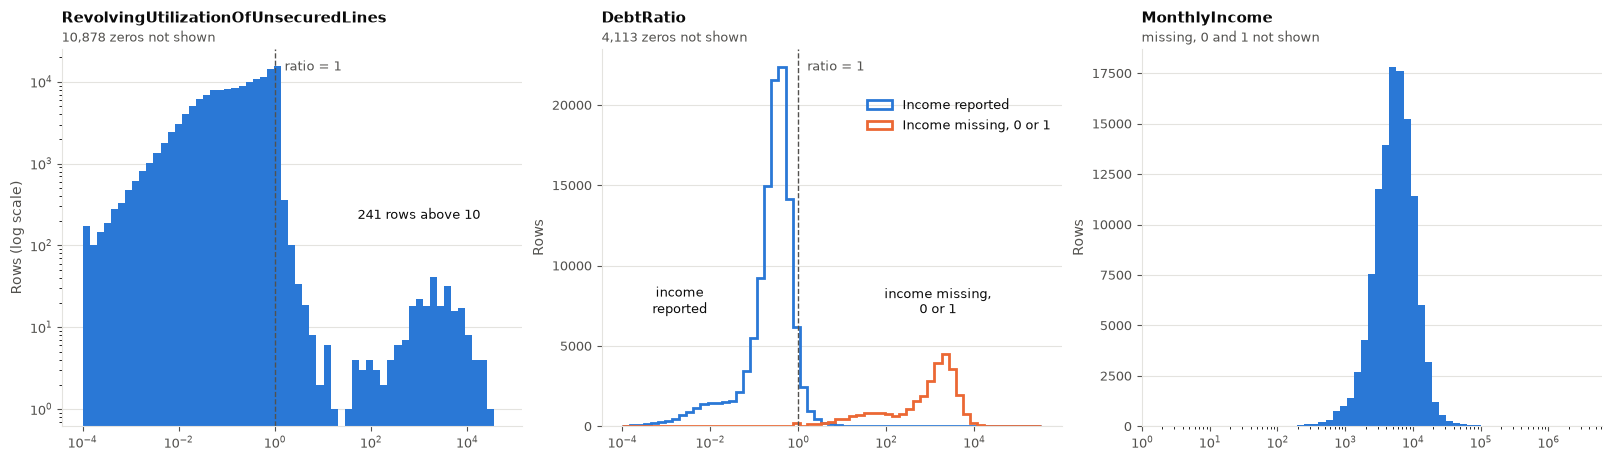

In [64]:
# Distributions on a log scale: values far outside the expected range show up as separate humps.
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"


def log_bins(values, low):
    return np.logspace(np.log10(low), np.log10(values.max()), 60)


def style(ax, title, subtitle, log_y=False):
    ax.set_xscale("log")
    if log_y:
        ax.set_yscale("log")
    ax.set_title(f"{title}\n", loc="left", fontsize=11, color=INK, fontweight="bold")
    ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED)
    ax.set_ylabel("Rows (log scale)" if log_y else "Rows", color=MUTED)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_color(GRID)


def ratio_line(ax):
    ax.axvline(1, color=MUTED, linestyle="--", linewidth=1)
    ax.text(1.6, 0.97, "ratio = 1", transform=ax.get_xaxis_transform(), fontsize=9, color=MUTED, va="top")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

# 1. Utilization
positive_util = util[util > 0].clip(lower=1e-4)
axes[0].hist(positive_util, bins=log_bins(positive_util, 1e-4), color=BLUE)
ratio_line(axes[0])
axes[0].annotate(f"{(util > 10).sum()} rows above 10", xy=(1000, 0.55), xycoords=("data", "axes fraction"), fontsize=9, color=INK, ha="center")
style(axes[0], "RevolvingUtilizationOfUnsecuredLines", f"{(util == 0).sum():,} zeros not shown", log_y=True)

# 2. DebtRatio, split by whether income is usable
debt = df["DebtRatio"]
positive_debt = debt[debt > 0].clip(lower=1e-4)
bins = log_bins(positive_debt, 1e-4)
usable = income_status.loc[positive_debt.index] == "reported"
axes[1].hist(positive_debt[usable], bins=bins, histtype="step", linewidth=2, color=BLUE, label="Income reported")
axes[1].hist(positive_debt[~usable], bins=bins, histtype="step", linewidth=2, color=ORANGE, label="Income missing, 0 or 1")
ratio_line(axes[1])
axes[1].annotate("income\nreported", xy=(2e-3, 0.3), xycoords=("data", "axes fraction"), fontsize=9, color=INK, ha="center")
axes[1].annotate("income missing,\n0 or 1", xy=(1500, 0.3), xycoords=("data", "axes fraction"), fontsize=9, color=INK, ha="center")
axes[1].legend(frameon=False, fontsize=9, labelcolor=INK, loc="upper right", bbox_to_anchor=(1, 0.9))
style(axes[1], "DebtRatio", f"{(debt == 0).sum():,} zeros not shown")

# 3. Monthly income
reported_income = income[income > 1]
axes[2].hist(reported_income, bins=log_bins(reported_income, 2), color=BLUE)
style(axes[2], "MonthlyIncome", "missing, 0 and 1 not shown")

plt.show()

**Findings**

- 2,239 rows have income 0 or 1 (1,634 zeros, 605 ones). Their `DebtRatio` behaves exactly like the missing-income rows: about 93% of values are above 1, against 4% when income is reported. Treat income ≤ 1 as missing.
- For the roughly 32,000 rows (21%) without usable income, `DebtRatio` is not a ratio. The plot shows it as a separate hump around 1,000. Proposal: set `DebtRatio` to missing on those rows and rely on the income flag. The raw value may still be useful as a separate "debt amount" feature; test that during feature engineering.
- With reported income, `DebtRatio` still has a long tail (99th percentile ≈ 2, max 450), which is plausible for heavily indebted borrowers. `MonthlyIncome` is also heavily right-skewed (99th percentile 25,000, max ≈ 3 million). Keep both, and cap them at the training 99.9th percentile if a linear model is used.

### 5.5 Other count columns

In [65]:
for col in ["NumberOfDependents", "NumberRealEstateLoansOrLines", "NumberOfOpenCreditLinesAndLoans"]:
    q = df[col].quantile([0.5, 0.99, 0.999])
    print(f"{col:32s} median={q[0.5]:.0f}  p99={q[0.99]:.0f}  p99.9={q[0.999]:.0f}  max={df[col].max():.0f}")

NumberOfDependents               median=0  p99=4  p99.9=6  max=20
NumberRealEstateLoansOrLines     median=1  p99=4  p99.9=9  max=54
NumberOfOpenCreditLinesAndLoans  median=8  p99=24  p99.9=34  max=58


**Findings:** these columns have long tails (20 dependents, 54 real-estate loans, 58 open credit lines), but no impossible values. Keep them, and cap at the 99.9th percentile only for linear models.

## 6. Train vs test consistency

The cleaning rules are only safe if the test file has the same quirks as the training file.

In [66]:
test_df = pd.read_csv("../data/raw/cs-test.csv")

print(f"Test rows: {len(test_df):,}")
print("Same columns as train:", list(test_df.columns) == list(df.columns))
print("Target values present in test:", test_df["SeriousDlqin2yrs"].notna().sum())
print("Test row numbers:", test_df["Unnamed: 0"].min(), "to", test_df["Unnamed: 0"].max())

Test rows: 101,503
Same columns as train: True
Target values present in test: 0
Test row numbers: 1 to 101503


In [67]:
def quirk_rates(data: pd.DataFrame) -> pd.Series:
    """Share of rows (%) affected by each issue found in this audit."""
    income = data["MonthlyIncome"]
    util = data["RevolvingUtilizationOfUnsecuredLines"]
    return pd.Series({
        "MonthlyIncome missing": income.isna().mean(),
        "MonthlyIncome 0 or 1": (income <= 1).mean(),
        "NumberOfDependents missing": data["NumberOfDependents"].isna().mean(),
        "past-due code 96/98": data[past_due_cols].isin([96, 98]).any(axis=1).mean(),
        "utilization > 1": (util > 1).mean(),
        "utilization > 10": (util > 10).mean(),
        "DebtRatio > 1": (data["DebtRatio"] > 1).mean(),
    }) * 100


pd.DataFrame({"train %": quirk_rates(df), "test %": quirk_rates(test_df)}).round(2)

,train %,test %
MonthlyIncome missing,19.82,19.81
MonthlyIncome 0 or 1,1.49,1.41
NumberOfDependents missing,2.62,2.59
past-due code 96/98,0.18,0.21
utilization > 1,2.21,2.15
utilization > 10,0.16,0.15
DebtRatio > 1,23.42,23.23


In [68]:
# Medians of every feature, as a quick check for distribution shift
feature_medians = pd.DataFrame({
    "train median": df[feature_cols].median(),
    "test median": test_df[feature_cols].median(),
})
feature_medians.round(3)

,train median,test median
RevolvingUtilizationOfUnsecuredLines,0.154,0.153
age,52.000,52.000
NumberOfTime30-59DaysPastDueNotWorse,0.000,0.000
DebtRatio,0.367,0.364
MonthlyIncome,5400.000,5400.000
NumberOfOpenCreditLinesAndLoans,8.000,8.000
NumberOfTimes90DaysLate,0.000,0.000
NumberRealEstateLoansOrLines,1.000,1.000
NumberOfTime60-89DaysPastDueNotWorse,0.000,0.000
NumberOfDependents,0.000,0.000


**Findings**

- The test file has the same columns and no target values. Every issue appears at almost the same rate, and the feature medians match, so both files come from the same population.
- All cleaning rules must therefore be applied to both files through **one** function. Any statistic the rules use (imputation medians, caps) must be computed on the training data only.
- `Unnamed: 0` restarts at 1 in the test file, which confirms it is a row number and not a borrower ID. It is only needed as `Id` in the submission file (`sampleEntry.csv`).

## 7. Summary: issues and proposed handling

| # | Issue | Evidence | Proposed handling |
|---|---|---|---|
| 1 | `Unnamed: 0` is a row number | Unique per row; restarts at 1 in the test file | Drop as a feature; keep it only as `Id` for the submission |
| 2 | Imbalanced target | 6.7% defaults (about 1 in 15) | Stratified splits; ROC-AUC and PR-AUC, not accuracy |
| 3 | Missing `MonthlyIncome` | 29,731 rows (19.8%); lower default rate | Keep rows; add an `income_missing` flag; impute the training median |
| 4 | `MonthlyIncome` of 0 or 1 | 2,239 rows; `DebtRatio` behaves like the missing-income rows | Treat as missing (same flag and imputation as #3) |
| 5 | Missing `NumberOfDependents` | 3,924 rows (2.6%), all also missing income | Add a flag; impute 0 (the median and mode) |
| 6 | `DebtRatio` is not a ratio without usable income | Median 1,159 vs 0.29; 93–94% above 1 vs 4% | Set to missing where income is missing or ≤ 1; test the raw value as a separate feature later |
| 7 | Past-due codes 96 and 98 | 269 rows, always all three columns; default rate 54.6% | Add a `past_due_code` flag; set the three counts to missing on those rows |
| 8 | Utilization above 10 | 241 rows, up to 50,708; default rate about 7% | Set to missing and add a flag; keep values between 1 and 10 (the riskiest group) |
| 9 | Age 0 | 1 row | Treat age < 18 as missing; impute the training median |
| 10 | Exact duplicates (ignoring the row number) | 609 extra copies (0.4%), mostly with missing income | Drop from the training data before splitting |
| 11 | Long right tails | Income up to ≈ 3 million; 54 real-estate loans; 20 dependents | Keep; cap at the training 99.9th percentile for linear models |
| 12 | Same issues in the test file | Rates match within 0.2 percentage points | One cleaning function for both files; all statistics from the training data only |

**Next steps**

1. Implement rules 1–11 as one cleaning function in `src/credit_risk_ai/data/`.
2. Add unit tests in `tests/test_data.py` that use the edge cases found here: age 0, the 96/98 rows, income 0 or 1, and utilization above 10.
3. Continue with feature exploration on the cleaned data.

In [4]:
from credit_risk_ai.data.load import load_train

df = load_train()
df.head()
print(df.shape, df.index.name, df.index.is_unique)
# (150000, 11) id True


(150000, 11) id True
